# Práctica 4. Ensambles: deserción estudiantil y Bank Marketing
Lucy Torres Durante
Se usan los mismos pliegues estratificados para todos los modelos.

In [3]:
import warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, joblib
from scipy.stats import loguniform, randint, uniform
from sklearn.base import clone
from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier, ExtraTreesClassifier,
    HistGradientBoostingClassifier, RandomForestClassifier, StackingClassifier, VotingClassifier)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, confusion_matrix, f1_score,
    make_scorer, recall_score)
from sklearn.model_selection import (RandomizedSearchCV, StratifiedKFold,
    cross_val_predict, cross_validate)
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (KBinsDiscretizer, LabelEncoder, OneHotEncoder,
    OrdinalEncoder, StandardScaler)
from sklearn.svm import SVC, LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.utils.class_weight import compute_sample_weight
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
SEED = 42
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

def evaluar(nombre, modelo, X, y, cv, clase, params=None):
    """F1 macro y sensibilidad de una clase con validación cruzada."""
    r = cross_validate(modelo, X, y, cv=cv, n_jobs=-1, params=params,
        scoring={"f1": "f1_macro",
                 "sens": make_scorer(recall_score, labels=[clase], average="macro")})
    return {"Modelo": nombre, "F1 macro": r["test_f1"].mean(), "Desv.": r["test_f1"].std(),
            "Sensibilidad": r["test_sens"].mean(), "Tiempo ajuste (s)": r["fit_time"].mean()}

## 1. Datos de deserción

In [5]:
train = pd.read_csv("./desercion-entrenamiento.csv")
CLASES = ["Dropout", "Enrolled", "Graduate"]
NOMINALES = ["Marital status", "Application mode", "Course", "Previous qualification",
             "Nacionality", "Mother's qualification", "Father's qualification",
             "Mother's occupation", "Father's occupation"]

sem2 = [c for c in train.columns if "2nd sem" in c]          # no se conocen al cierre del 1er semestre
X = train.drop(columns=["id", "Target"] + sem2)
y = LabelEncoder().fit_transform(train["Target"])           # 0,1,2
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

print(X.shape, np.bincount(y))

(3539, 30) [1137  635 1767]


## 2. Los cinco modelos de la Práctica 3 (hiperparámetros ya optimizados)

In [6]:
ohe = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)
prep_ord = ColumnTransformer([("nom", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1), NOMINALES)], remainder="passthrough")
prep_esc = ColumnTransformer([("nom", ohe, NOMINALES)], remainder=StandardScaler())
prep_disc = ColumnTransformer([("nom", ohe, NOMINALES)], remainder=KBinsDiscretizer(n_bins=10, encode="onehot-dense", strategy="quantile"))
prep_ohe = ColumnTransformer([("nom", ohe, NOMINALES)], remainder="passthrough")

base = {
    "Árbol de decisión": Pipeline([("prep", prep_ord), ("clf", DecisionTreeClassifier(
        max_depth=4, ccp_alpha=0.0010970529245749178, class_weight="balanced", random_state=SEED))]),
    "Naive Bayes": Pipeline([("prep", prep_disc), ("clf", MultinomialNB(alpha=0.4159837801719407))]),
    "kNN": Pipeline([("prep", prep_esc), ("clf", KNeighborsClassifier(n_neighbors=8))]),
    "SVM": Pipeline([("prep", prep_esc), ("clf", SVC(C=1.36885572763103, gamma=0.011948354480999268,
        class_weight="balanced", random_state=SEED))]),
    "Regresión logística": Pipeline([("prep", prep_esc), ("clf", LogisticRegression(
        C=0.17885301261862016, l1_ratio=0.75, solver="saga", max_iter=3000,
        class_weight="balanced", random_state=SEED))]),
}

filas = [dict(evaluar(n, m, X, y, cv, 1), Familia="Base") for n, m in base.items()]
pd.DataFrame(filas).sort_values("F1 macro", ascending=False).round(4)

,Modelo,F1 macro,Desv.,Sensibilidad,Tiempo ajuste (s),Familia
4,Regresión logística,0.6787,0.0133,0.5748,2.2662,Base
3,SVM,0.6735,0.0118,0.5984,0.4572,Base
0,Árbol de decisión,0.6404,0.0123,0.4724,0.0233,Base
1,Naive Bayes,0.6022,0.0138,0.3937,0.0434,Base
2,kNN,0.5845,0.0120,0.2205,0.0207,Base


## 3. Varianza: árbol sin poda vs. bagging de esos árboles

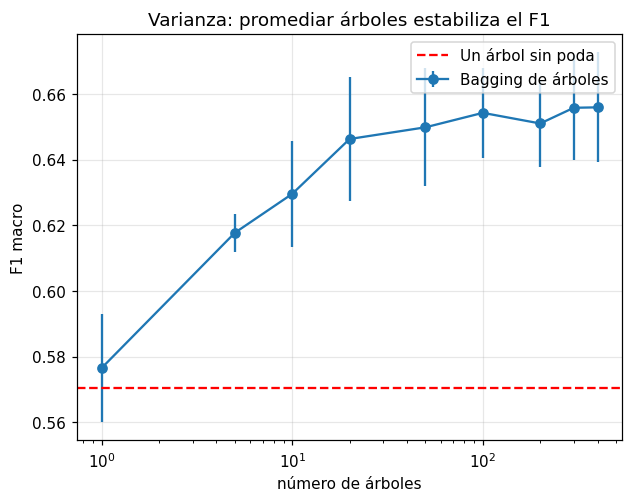

Árbol sin poda: 0.5705 | Bagging 400: 0.656


In [7]:
ns = [1, 5, 10, 20, 50, 100, 200, 300, 400]
f1_bag, f1_arbol = np.zeros((5, len(ns))), np.zeros(5)

for j, (tr, va) in enumerate(cv.split(X, y)):
    arbol = DecisionTreeClassifier(random_state=SEED).fit(X.iloc[tr], y[tr])
    f1_arbol[j] = f1_score(y[va], arbol.predict(X.iloc[va]), average="macro")
    bag = BaggingClassifier(DecisionTreeClassifier(random_state=SEED), n_estimators=1,
                            warm_start=True, random_state=SEED)
    for i, n in enumerate(ns):            # warm_start: solo agrega árboles nuevos
        bag.set_params(n_estimators=n).fit(X.iloc[tr], y[tr])
        f1_bag[j, i] = f1_score(y[va], bag.predict(X.iloc[va]), average="macro")

plt.errorbar(ns, f1_bag.mean(0), f1_bag.std(0), marker="o", label="Bagging de árboles")
plt.axhline(f1_arbol.mean(), color="r", ls="--", label="Un árbol sin poda")
plt.xscale("log"); plt.xlabel("número de árboles"); plt.ylabel("F1 macro"); plt.legend()
plt.title("Varianza: promediar árboles estabiliza el F1"); plt.show()
print("Árbol sin poda:", f1_arbol.mean().round(4), "| Bagging 400:", f1_bag[:, -1].mean().round(4))

## 4. Sesgo: tocón vs. AdaBoost de tocones

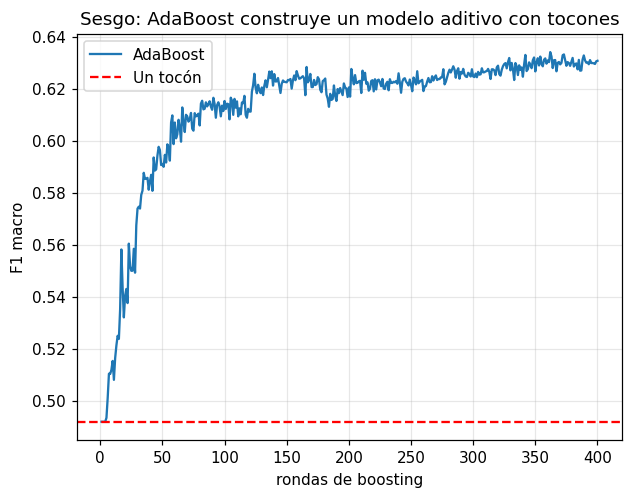

Tocón: 0.492 | AdaBoost 400: 0.6308


In [8]:
f1_ada, f1_tocon = np.zeros((5, 400)), np.zeros(5)

for j, (tr, va) in enumerate(cv.split(X, y)):
    tocon = DecisionTreeClassifier(max_depth=1, random_state=SEED).fit(X.iloc[tr], y[tr])
    f1_tocon[j] = f1_score(y[va], tocon.predict(X.iloc[va]), average="macro")
    ada = AdaBoostClassifier(DecisionTreeClassifier(max_depth=1, random_state=SEED),
                             n_estimators=400, random_state=SEED).fit(X.iloc[tr], y[tr])
    f1_ada[j] = [f1_score(y[va], p, average="macro") for p in ada.staged_predict(X.iloc[va])]

plt.plot(np.arange(1, 401), f1_ada.mean(0), label="AdaBoost")
plt.axhline(f1_tocon.mean(), color="r", ls="--", label="Un tocón")
plt.xlabel("rondas de boosting"); plt.ylabel("F1 macro"); plt.legend()
plt.title("Sesgo: AdaBoost construye un modelo aditivo con tocones"); plt.show()
print("Tocón:", f1_tocon.mean().round(4), "| AdaBoost 400:", f1_ada[:, -1].mean().round(4))

## 5. Combinar los cinco modelos base (votación y stacking)

El SVM se calibra dentro de cada pliegue para poder entregar probabilidades.

In [9]:
base_cal = dict(base)
base_cal["SVM"] = CalibratedClassifierCV(base["SVM"], method="sigmoid", cv=5)

combinados = {
    "Votación dura": VotingClassifier(list(base.items()), voting="hard"),
    "Votación suave": VotingClassifier(list(base_cal.items()), voting="soft"),
    "Stacking": StackingClassifier(list(base_cal.items()), cv=5, stack_method="predict_proba",
        final_estimator=LogisticRegression(max_iter=3000, class_weight="balanced", random_state=SEED)),
}
filas += [dict(evaluar(n, m, X, y, cv, 1), Familia="Combinación") for n, m in combinados.items()]

# correlación entre los errores de los cinco modelos base
errores = pd.DataFrame({n: cross_val_predict(m, X, y, cv=cv, n_jobs=-1) != y for n, m in base.items()})
print(errores.corr().round(2))
print("Correlación media:", errores.corr().values[~np.eye(5, dtype=bool)].mean().round(3))

                     Árbol de decisión  Naive Bayes   kNN   SVM  \
Árbol de decisión                 1.00         0.53  0.47  0.63   
Naive Bayes                       0.53         1.00  0.43  0.52   
kNN                               0.47         0.43  1.00  0.51   
SVM                               0.63         0.52  0.51  1.00   
Regresión logística               0.59         0.50  0.47  0.77   

                     Regresión logística  
Árbol de decisión                   0.59  
Naive Bayes                         0.50  
kNN                                 0.47  
SVM                                 0.77  
Regresión logística                 1.00  
Correlación media: 0.544


## 6. Random Forest, Extra-Trees, XGBoost y LightGBM optimizados (60 configuraciones c/u)

Random Forest (opt.) | mejor F1 búsqueda: 0.6834
Extra-Trees (opt.) | mejor F1 búsqueda: 0.6682
XGBoost (opt.) | mejor F1 búsqueda: 0.6935
LightGBM (opt.) | mejor F1 búsqueda: 0.6904


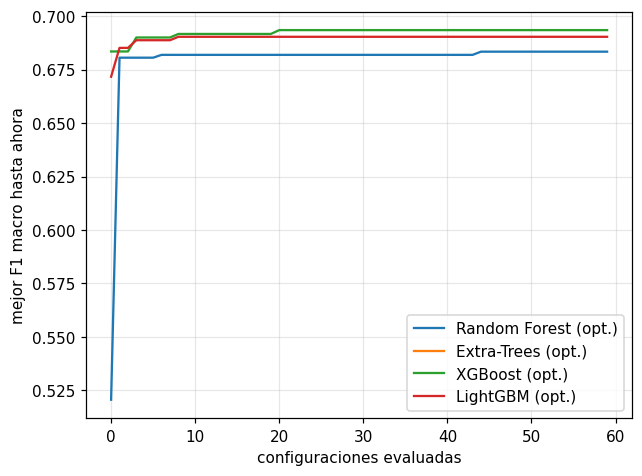

In [10]:
esp_arboles = {
    "prep": [prep_ohe, prep_ord],
    "clf__n_estimators": [300, 500],
    "clf__max_features": ["sqrt", "log2", 0.2, 0.4, 0.6],
    "clf__min_samples_leaf": [1, 2, 3, 5, 8, 12, 20],
    "clf__max_depth": [None, 6, 10, 15, 20],
    "clf__criterion": ["gini", "entropy", "log_loss"],
    "clf__class_weight": [None, "balanced", "balanced_subsample"],
}
esp_et = dict(esp_arboles, clf__bootstrap=[False, True], clf__max_samples=[0.7, 0.9, 1.0])
esp_xgb = {
    "clf__n_estimators": [300, 600], "clf__learning_rate": loguniform(0.01, 0.3),
    "clf__max_depth": randint(3, 9), "clf__min_child_weight": randint(1, 10),
    "clf__reg_lambda": loguniform(1e-3, 10), "clf__reg_alpha": loguniform(1e-3, 10),
    "clf__subsample": uniform(0.6, 0.4), "clf__colsample_bytree": uniform(0.5, 0.5),
    "clf__gamma": loguniform(1e-4, 1),
}
esp_lgbm = {
    "clf__n_estimators": [300, 600], "clf__learning_rate": loguniform(0.01, 0.3),
    "clf__num_leaves": randint(8, 64), "clf__max_depth": [-1, 4, 6, 8, 12],
    "clf__min_child_samples": randint(5, 50), "clf__reg_lambda": loguniform(1e-3, 10),
    "clf__reg_alpha": loguniform(1e-3, 10), "clf__subsample": uniform(0.6, 0.4),
    "clf__subsample_freq": [1], "clf__colsample_bytree": uniform(0.5, 0.5),
    "clf__class_weight": [None, "balanced"],
}

# XGBoost multiclase no admite class_weight: se usan pesos por muestra
w = compute_sample_weight("balanced", y)

a_optimizar = {
    "Random Forest (opt.)": (RandomForestClassifier(random_state=SEED), esp_arboles),
    "Extra-Trees (opt.)": (ExtraTreesClassifier(random_state=SEED), esp_et),
    "XGBoost (opt.)": (XGBClassifier(random_state=SEED, verbosity=0, eval_metric="mlogloss"), esp_xgb),
    "LightGBM (opt.)": (LGBMClassifier(random_state=SEED, verbosity=-1), esp_lgbm),
}

mejores = {}
params_xgb = {"clf__sample_weight": w}
for nombre, (clf, espacio) in a_optimizar.items():
    pipe = Pipeline([("prep", prep_ohe), ("clf", clf)])
    busqueda = RandomizedSearchCV(pipe, espacio, n_iter=60, scoring="f1_macro", cv=cv,
                                  n_jobs=-1, random_state=SEED)
    fit_params = params_xgb if "XGB" in nombre else {}
    busqueda.fit(X, y, **fit_params)
    mejores[nombre] = busqueda.best_estimator_
    filas.append(dict(evaluar(nombre, busqueda.best_estimator_, X, y, cv, 1,
                              params=fit_params or None), Familia="Optimizado"))
    print(nombre, "| mejor F1 búsqueda:", round(busqueda.best_score_, 4))

    scores = busqueda.cv_results_["mean_test_score"]
    plt.plot(np.maximum.accumulate(scores), label=nombre)
plt.xlabel("configuraciones evaluadas"); plt.ylabel("mejor F1 macro hasta ahora"); plt.legend(); plt.show()

## 7. Tabla final de deserción

,Modelo,F1 macro,Desv.,Sensibilidad,Tiempo ajuste (s),Familia
1,XGBoost (opt.),0.6935,0.0112,0.5528,2.3802,Optimizado
2,LightGBM (opt.),0.6904,0.0107,0.5906,3.1566,Optimizado
3,Random Forest (opt.),0.6834,0.0129,0.5228,7.4795,Optimizado
4,Stacking,0.6798,0.0085,0.5953,23.6092,Combinación
5,Regresión logística,0.6787,0.0133,0.5748,2.2662,Base
6,Votación dura,0.6785,0.0081,0.5087,2.5948,Combinación
7,SVM,0.6735,0.0118,0.5984,0.4572,Base
8,Extra-Trees (opt.),0.6682,0.0093,0.4740,3.4141,Optimizado
9,Votación suave,0.6673,0.0073,0.4016,4.4482,Combinación
10,Árbol de decisión,0.6404,0.0123,0.4724,0.0233,Base


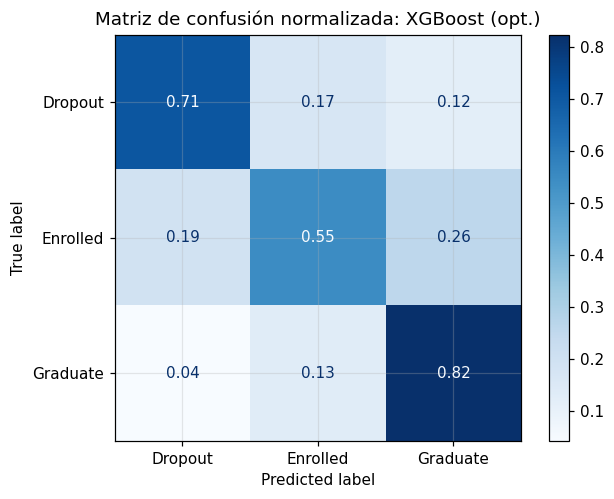

In [11]:
tabla = pd.DataFrame(filas).sort_values("F1 macro", ascending=False).reset_index(drop=True)
tabla.index += 1
display(tabla.round(4))

mejor = tabla.iloc[0]["Modelo"]
todos = {**base, **combinados, **mejores}
params = params_xgb if "XGB" in mejor else None
pred = cross_val_predict(todos[mejor], X, y, cv=cv, params=params)
cm = confusion_matrix(y, pred)
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=CLASES).plot(values_format=".2f", cmap="Blues")
plt.title(f"Matriz de confusión normalizada: {mejor}"); plt.show()

# Parte 2. Bank Marketing

Se elimina `duration` (solo se conoce después de la llamada). `pdays=999` significa "nunca contactado", así que se separa en dos variables. Estas transformaciones no aprenden nada de los datos, por eso se pueden hacer antes de la validación cruzada sin fuga de información.

In [13]:
df = pd.read_csv("./bank-additional-full.csv", sep=";")
y_b = (df["y"] == "yes").astype(int).to_numpy()
Xb = df.drop(columns=["duration", "y"])
Xb["fue_contactado_antes"] = (Xb["pdays"] != 999).astype(int)
Xb["dias_desde_ultimo_contacto"] = Xb["pdays"].where(Xb["pdays"] != 999, 0)
Xb = Xb.drop(columns="pdays")

cat = Xb.select_dtypes(exclude="number").columns.tolist()
num = [c for c in Xb.columns if c not in cat]
cv_b = StratifiedKFold(n_splits=5, shuffle=True, random_state=2026)

ohe_b = OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=10, sparse_output=False)
prep_lin = ColumnTransformer([("cat", ohe_b, cat), ("num", StandardScaler(), num)])   # logística, kNN, SVM
prep_arb = ColumnTransformer([("cat", ohe_b, cat), ("num", "passthrough", num)])      # árboles y Naive Bayes

print(Xb.shape, "| positivos:", y_b.mean().round(4))

(41188, 20) | positivos: 0.1127


## 8. Modelos individuales

In [14]:
modelos_b = {
    "Dummy": (prep_arb, DummyClassifier(strategy="prior")),
    "Regresión logística": (prep_lin, LogisticRegression(C=0.2, max_iter=2000, class_weight="balanced", random_state=SEED)),
    "Árbol de decisión": (prep_arb, DecisionTreeClassifier(max_depth=8, min_samples_leaf=20, class_weight="balanced", random_state=SEED)),
    "GaussianNB": (prep_arb, GaussianNB()),
    "kNN": (prep_lin, KNeighborsClassifier(n_neighbors=100, weights="distance")),
    "SVM lineal": (prep_lin, LinearSVC(C=0.5, class_weight="balanced", max_iter=5000, random_state=SEED)),
    "HistGradientBoosting": (prep_arb, HistGradientBoostingClassifier(learning_rate=0.06, max_iter=400,
        l2_regularization=1.0, class_weight="balanced", early_stopping=False, random_state=SEED)),
    "Random Forest": (prep_arb, RandomForestClassifier(n_estimators=300, min_samples_leaf=5,
        class_weight="balanced_subsample", random_state=SEED)),
    "Extra-Trees": (prep_arb, ExtraTreesClassifier(n_estimators=300, min_samples_leaf=5,
        class_weight="balanced", random_state=SEED)),
    "XGBoost (base)": (prep_arb, XGBClassifier(n_estimators=500, learning_rate=0.05, max_depth=5,
        min_child_weight=3, subsample=0.8, colsample_bytree=0.8, scale_pos_weight=8,
        verbosity=0, random_state=SEED)),
    "XGBoost (opt.)": (prep_arb, XGBClassifier(n_estimators=600, learning_rate=0.12106896936002161,
        max_depth=8, min_child_weight=2, reg_alpha=9.307782732027235, reg_lambda=1.0922573731641068,
        scale_pos_weight=3, subsample=0.8099025726528951, colsample_bytree=0.5102922471479012,
        gamma=3.8696122574142664, verbosity=0, random_state=SEED)),
    "LightGBM (base)": (prep_arb, LGBMClassifier(n_estimators=500, learning_rate=0.05, subsample=0.8,
        subsample_freq=1, colsample_bytree=0.8, class_weight="balanced", verbosity=-1, random_state=SEED)),
    "LightGBM (opt.)": (prep_arb, LGBMClassifier(n_estimators=600, learning_rate=0.019709599406471233,
        num_leaves=48, max_depth=12, min_child_samples=11, reg_alpha=0.5804314717414073,
        reg_lambda=0.1890710249553741, subsample=0.9746919954946938, subsample_freq=1,
        colsample_bytree=0.7560465291496405, class_weight="balanced", verbosity=-1, random_state=SEED)),
    "CatBoost": (prep_arb, CatBoostClassifier(iterations=500, learning_rate=0.05, depth=6,
        auto_class_weights="Balanced", verbose=0, random_seed=SEED)),
}
pipes_b = {n: Pipeline([("prep", p), ("clf", c)]) for n, (p, c) in modelos_b.items()}

filas_b = [evaluar(n, m, Xb, y_b, cv_b, 1) for n, m in pipes_b.items()]

## 9. Ensambles de los mejores modelos

In [15]:
elegidos = ["Random Forest", "XGBoost (opt.)", "CatBoost", "LightGBM (opt.)",
            "HistGradientBoosting", "Regresión logística"]
estimadores = [(n, pipes_b[n]) for n in elegidos]

for nombre, tipo in [("Votación dura", "hard"), ("Votación suave", "soft")]:
    pipes_b[nombre] = VotingClassifier(estimadores, voting=tipo)
    filas_b.append(evaluar(nombre, pipes_b[nombre], Xb, y_b, cv_b, 1))

## 10. Umbral de decisión del mejor modelo

El umbral se elige solo con los datos de entrenamiento de cada pliegue (validación cruzada interna) para no usar la validación.

In [16]:
mejor_b = pd.DataFrame(filas_b).sort_values("F1 macro").iloc[-1]["Modelo"]
umbrales = np.linspace(0.1, 0.9, 81)
f1_u, sens_u = [], []

for tr, va in cv_b.split(Xb, y_b):
    m = clone(pipes_b[mejor_b])
    p_tr = cross_val_predict(m, Xb.iloc[tr], y_b[tr], cv=3, method="predict_proba")[:, 1]
    u = umbrales[np.argmax([f1_score(y_b[tr], p_tr >= t, average="macro") for t in umbrales])]
    m.fit(Xb.iloc[tr], y_b[tr])
    pred = m.predict_proba(Xb.iloc[va])[:, 1] >= u
    f1_u.append(f1_score(y_b[va], pred, average="macro"))
    sens_u.append(recall_score(y_b[va], pred))

filas_b.append({"Modelo": "Mejor modelo + umbral", "F1 macro": np.mean(f1_u), "Desv.": np.std(f1_u),
                "Sensibilidad": np.mean(sens_u), "Tiempo ajuste (s)": np.nan})

## 11. Tabla final de Bank Marketing y modelo guardado

,Modelo,F1 macro,Desv.,Sensibilidad,Tiempo ajuste (s)
1,XGBoost (opt.),0.7177,0.0074,0.5478,4.2869
2,Random Forest,0.7125,0.0059,0.5933,11.5161
3,Votación suave,0.7096,0.0041,0.6047,46.4478
4,Votación dura,0.7086,0.0039,0.5978,48.1561
5,LightGBM (opt.),0.6941,0.0042,0.6239,7.6886
6,Extra-Trees,0.6913,0.0058,0.6080,12.6168
7,LightGBM (base),0.6895,0.0040,0.6205,4.4510
8,CatBoost,0.6882,0.0033,0.6353,14.4027
9,HistGradientBoosting,0.6876,0.0054,0.6216,6.3479
10,XGBoost (base),0.6839,0.0056,0.6256,4.8048


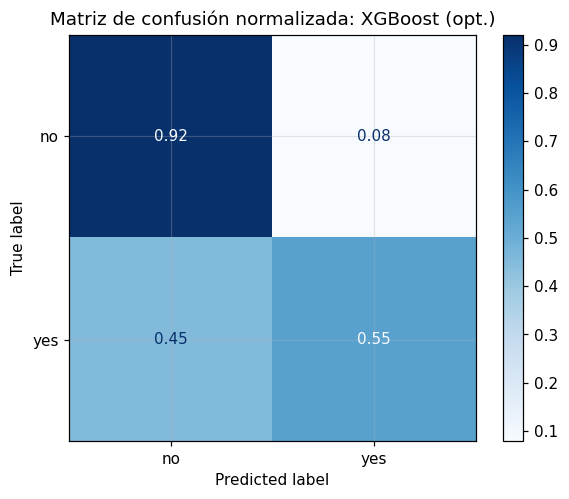

Guardado: XGBoost (opt.)


In [17]:
tabla_b = pd.DataFrame(filas_b).sort_values("F1 macro", ascending=False).reset_index(drop=True)
tabla_b.index += 1
display(tabla_b.round(4))

mejor_b = tabla_b[tabla_b["Modelo"] != "Mejor modelo + umbral"].iloc[0]["Modelo"]
pred = cross_val_predict(pipes_b[mejor_b], Xb, y_b, cv=cv_b)
cm = confusion_matrix(y_b, pred)
ConfusionMatrixDisplay(cm / cm.sum(1, keepdims=True), display_labels=["no", "yes"]).plot(values_format=".2f", cmap="Blues")
plt.title(f"Matriz de confusión normalizada: {mejor_b}"); plt.show()

modelo_final = clone(pipes_b[mejor_b]).fit(Xb, y_b)
joblib.dump(modelo_final, "lucy-mejor_modelo_bank.joblib")
print("Guardado:", mejor_b)

## Conclusiones

1. **Bagging reduce varianza**: el árbol sin poda sobreajusta; promediar árboles bootstrap sube el F1 y estabiliza la curva.
2. **Boosting reduce sesgo**: un tocón es muy débil, pero AdaBoost lo convierte en un modelo aditivo más expresivo.
3. **Combinar modelos ya buenos aporta poco** si sus errores están correlacionados (votación y stacking quedan al nivel del mejor modelo base).
4. **El ganador depende del problema**: con pocos datos (deserción) los modelos lineales regularizados compiten; con muchos datos e interacciones (Bank Marketing) XGBoost y Random Forest destacan.